# 02 — Compartment analyses (full 5k panel)

## Questions
1. Does compartment size differ between control and mtDSB? 
2. Do cell types (microglia, OL lineage) change within compartments?
3. Do compartments change their spatial neighbours?
4. Which genes change in the myelinated compartments 3 and 10?


In [1]:
import logging
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import cellcharter as cc
import matplotlib.pyplot as plt
import seaborn as sns
import compartment_stats as cs

logging.getLogger('lightning.pytorch').setLevel(logging.ERROR)

DATA = '../data/adata_5k_cellcharter.h5ad'
RES = '../results/cellcharter'
SAMPLE, COND, COMP, CT_WORK, TP = 'sample_id', 'condition', 'compartment', 'cell_class_work', 'timepoint'
RESP = 'responder_status'
PRIMARY = ['3', '10']
MIN_CELLS = 100

adata = ad.read_h5ad(DATA, backed='r')     # X stays on disk; counts are read only for the pseudobulk subsets
obs = adata.obs.copy()
info = cs.sample_table(obs, SAMPLE, [COND, TP, RESP])
info['_all'] = 'all'
info

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


,condition,timepoint,responder_status,_all
sample_id,,,,
RB4282,control,P60,control,all
RB4350,control,P60,control,all
RB4401,mtDSB,P60,responder,all
RB4403,mtDSB,P60,non-responder,all
RB4405,mtDSB,P60,responder,all
RB4498,control,P60,control,all
RB4620,control,P21,control,all
RB4627,mtDSB,P21,responder,all
RB4630,mtDSB,P21,non-responder,all


In [2]:
COMPARISONS = {
    'mtDSB vs control': dict(cond_key=COND, treat='mtDSB', ref='control', strata_key=TP),           # primary
    'responder vs control': dict(cond_key=RESP, treat='responder', ref='control', strata_key='_all'),  # secondary
}

def test_both(long, by, family=None):
    # run test_fractions for each comparison; BH-FDR within comparison (and family)
    out = []
    for name, kw in COMPARISONS.items():
        r = cs.test_fractions(long, info, SAMPLE, by=by, **kw)
        r = r.rename(columns={f"mean_{kw['treat']}": 'mean_treat', f"mean_{kw['ref']}": 'mean_ref'})
        out.append(cs.add_fdr(r, family=family).assign(comparison=name))
    return pd.concat(out, ignore_index=True)


COMP_ORDER = sorted(obs[COMP].cat.categories, key=int)

def strip_by_mouse(df, x, y, col=None, title=None, fname=None, **kw):
    # one dot per mouse; colour = control / non-responder / responder, marker = DOX timepoint
    d = df.join(info, on=SAMPLE)
    return cs.strip_by_mouse(d, x, y, group_key=RESP, tp_key=TP, col=col, title=title,
                             fname=f'{RES}/{fname}' if fname else None, **kw)

## 1. Compartment size per section
Note: the cutting level differs between sections, which changes compartment sizes independently of condition. 

,label,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,logOR,p_qb,padj_perm,padj_qb,comparison
0,0,0.0312,0.0143,-0.6490,0.1050,400,6,6,-0.6581,0.1235,0.9700,0.9116,mtDSB vs control
1,1,0.0729,0.0780,0.0867,0.6800,400,6,6,0.0478,0.8249,0.9700,0.9116,mtDSB vs control
2,10,0.0613,0.0581,-0.0580,0.6200,400,6,6,-0.0377,0.7385,0.9700,0.9116,mtDSB vs control
3,11,0.0360,0.0326,-0.1624,0.4300,400,6,6,-0.0841,0.6782,0.9700,0.9116,mtDSB vs control
4,12,0.1587,0.1609,0.0241,0.8000,400,6,6,-0.0107,0.9116,0.9700,0.9116,mtDSB vs control
5,13,0.1063,0.1138,0.0227,0.9450,400,6,6,0.1035,0.6925,0.9700,0.9116,mtDSB vs control
6,2,0.0913,0.1003,0.1107,0.2050,400,6,6,0.0895,0.3382,0.9700,0.9116,mtDSB vs control
7,3,0.0530,0.0667,0.1893,0.2950,400,6,6,0.2894,0.1504,0.9700,0.9116,mtDSB vs control
8,4,0.1172,0.1098,-0.0758,0.5050,400,6,6,-0.0833,0.4710,0.9700,0.9116,mtDSB vs control
9,5,0.0187,0.0198,-0.0224,0.9700,400,6,6,0.0905,0.7442,0.9700,0.9116,mtDSB vs control


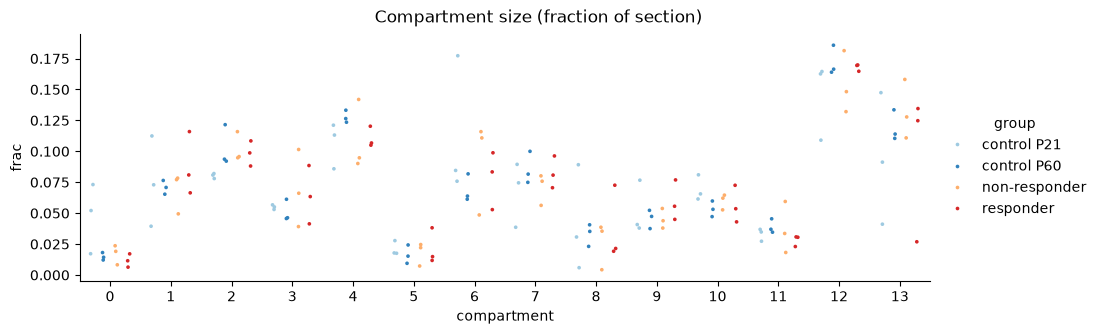

In [3]:
obs['_section'] = 'all'
size = cs.fraction_table(obs, SAMPLE, '_section', COMP, list(obs[COMP].cat.categories), min_cells=0)
size_res = test_both(size, by=['label'])
size_res.to_csv(f'{RES}/test_compartment_size.csv', index=False)
display(size_res.round(4))

strip_by_mouse(size.rename(columns={'label': COMP}), x=COMP, y='frac', aspect=3, order=COMP_ORDER,
               title='Compartment size (fraction of section)', fname='compartment_size_per_mouse.png')

## 2. Cell types within compartments
Fraction of each cell type among the cells of a compartment, per mouse. FDR within each comparison and cell type.

In [4]:
CELLTYPES = ['Microglia', 'Oligodendrocytes', 'DA-Oligodendrocytes', 'COP/NFOL', 'OPC', 'Astrocytes']
ctf = cs.fraction_table(obs, SAMPLE, COMP, CT_WORK, CELLTYPES, min_cells=MIN_CELLS)
ct_res = test_both(ctf, by=['label', COMP], family='label')
ct_res['primary'] = ct_res[COMP].isin(PRIMARY)
ct_res.to_csv(f'{RES}/test_celltype_in_compartment.csv', index=False)
display(ct_res[ct_res['primary']].sort_values(['comparison', 'label']).round(4))

/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/hom

,label,compartment,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,logOR,p_qb,padj_perm,padj_qb,comparison,primary
3,Astrocytes,3,0.1681,0.1740,0.0255,0.8650,400,6,6,0.1452,0.3164,0.9692,0.6180,mtDSB vs control,True
10,Astrocytes,10,0.1341,0.1461,0.0902,0.3550,400,6,6,0.0789,0.4017,0.9170,0.6180,mtDSB vs control,True
17,COP/NFOL,3,0.0049,0.0065,0.2058,0.4550,400,6,6,0.3235,0.2989,0.9850,0.9730,mtDSB vs control,True
24,COP/NFOL,10,0.0093,0.0096,0.0398,0.7950,400,6,6,-0.0219,0.8885,0.9850,1.0000,mtDSB vs control,True
31,DA-Oligodendrocytes,3,0.0025,0.0986,2.4494,0.1050,400,6,6,3.6086,0.2644,0.3033,0.2847,mtDSB vs control,True
38,DA-Oligodendrocytes,10,0.0060,0.1299,2.0499,0.1350,400,6,6,2.9920,0.2344,0.3033,0.2750,mtDSB vs control,True
45,Microglia,3,0.0339,0.0571,0.4732,0.0400,400,6,6,0.4892,0.0771,0.2450,0.2595,mtDSB vs control,True
52,Microglia,10,0.0236,0.0303,0.2026,0.2950,400,6,6,0.1999,0.3214,0.5338,0.6018,mtDSB vs control,True
59,OPC,3,0.0269,0.0265,0.0076,0.9650,400,6,6,-0.0274,0.8094,1.0000,0.9991,mtDSB vs control,True
66,OPC,10,0.0166,0.0194,0.1303,0.3800,400,6,6,0.1393,0.3383,0.9380,0.9991,mtDSB vs control,True


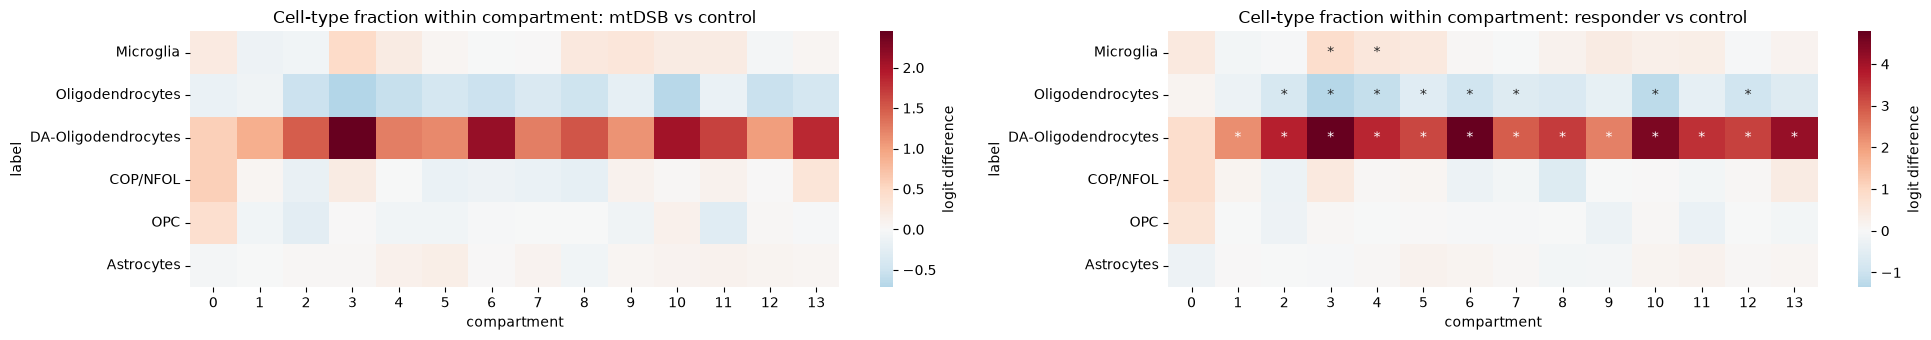

In [5]:
# overview: logit difference (treat - control), * = padj_perm < 0.1 (exploratory overview)
fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(20, 3.5))
for ax, name in zip(axes, COMPARISONS):
    r = ct_res[ct_res['comparison'] == name]
    eff = r.pivot(index='label', columns=COMP, values='effect').reindex(index=CELLTYPES)
    padj = r.pivot(index='label', columns=COMP, values='padj_perm').reindex(index=CELLTYPES)
    eff = eff[sorted(eff.columns, key=int)]
    sns.heatmap(eff, cmap='RdBu_r', center=0, annot=padj[eff.columns].map(lambda p: '*' if p < 0.1 else ''),
                fmt='', ax=ax, cbar_kws={'label': 'logit difference'})
    ax.set_title(f'Cell-type fraction within compartment: {name}')
fig.tight_layout()
fig.savefig(f'{RES}/celltype_in_compartment_effect.png', dpi=150, bbox_inches='tight')

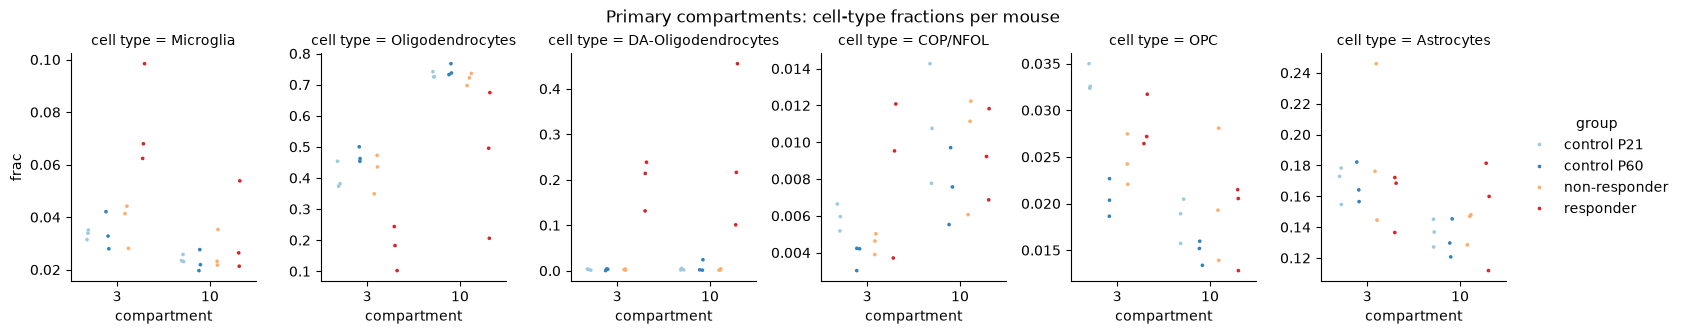

In [6]:
d = ctf[ctf[COMP].isin(PRIMARY)].rename(columns={'label': 'cell type'}).astype({COMP: str})
strip_by_mouse(d, x=COMP, y='frac', col='cell type', sharey=False, aspect=0.8, order=PRIMARY,
               title='Primary compartments: cell-type fractions per mouse', fname='celltype_primary_per_mouse.png')

OL state shift: DA-OLs as a fraction of all mature OLs (OL + DA-OL) in each compartment, per mouse.

,compartment,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,logOR,p_qb,padj_perm,padj_qb,comparison
0,2,0.0073,0.1949,1.9269,0.1900,400,6,6,3.3072,0.1722,0.2500,0.2794,mtDSB vs control
1,3,0.0056,0.2680,2.8472,0.1100,400,6,6,3.8982,0.2836,0.2500,0.2836,mtDSB vs control
2,4,0.0181,0.2738,1.6813,0.2500,400,6,6,2.7959,0.1172,0.2500,0.2794,mtDSB vs control
3,5,0.0175,0.2339,1.7098,0.1850,200,5,6,2.4037,0.1761,0.2500,0.2794,mtDSB vs control
4,6,0.0042,0.2006,2.5586,0.1450,400,6,6,3.3437,0.2521,0.2500,0.2794,mtDSB vs control
5,7,0.0160,0.1609,1.5659,0.1700,400,6,6,2.3409,0.1315,0.2500,0.2794,mtDSB vs control
6,8,0.0079,0.1567,1.4091,0.1550,200,5,6,2.5619,0.0253,0.2500,0.2794,mtDSB vs control
7,9,0.0435,0.2496,1.4345,0.2400,100,5,5,1.9614,0.2535,0.2500,0.2794,mtDSB vs control
8,10,0.0080,0.1887,2.2029,0.1350,400,6,6,3.0603,0.2559,0.2500,0.2794,mtDSB vs control
9,11,0.0121,0.1739,1.7988,0.1750,400,6,6,2.4870,0.2561,0.2500,0.2794,mtDSB vs control


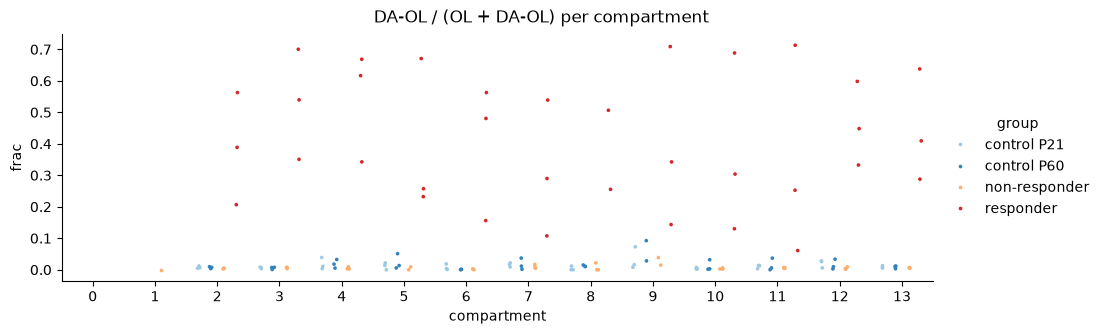

In [7]:
mature = obs[obs[CT_WORK].isin(['Oligodendrocytes', 'DA-Oligodendrocytes'])]
da_share = cs.fraction_table(mature, SAMPLE, COMP, CT_WORK, ['DA-Oligodendrocytes'], min_cells=50)
da_res = test_both(da_share, by=[COMP])
da_res.to_csv(f'{RES}/test_da_ol_share.csv', index=False)
display(da_res.round(4))
strip_by_mouse(da_share, x=COMP, y='frac', aspect=3, order=COMP_ORDER, title='DA-OL / (OL + DA-OL) per compartment',
               fname='da_ol_share_per_mouse.png')

## 3. Compartment neighbourhoods, per section
`cc.gr.diff_nhood_enrichment` pools all cells of a condition and stores **control − mtDSB** (key `control_mtDSB`; checked
against the per-section values, correlation −0.97). The earlier plot therefore showed **positive = stronger in control**:
8↔13 is weaker in mtDSB, and 8↔7 and 0↔11 are stronger in mtDSB.

Here `cc.gr.nhood_enrichment` is computed in each section separately (default `only_inter=True`, `symmetric=False`:
row = source compartment, value = observed − expected fraction of its inter-compartment links going to the column
compartment). Each ordered pair is then tested across mice. Effect = **treat − control**.

In [8]:
nh = cs.per_section_nhood(obs, adata.obsp['cc_connectivities'], SAMPLE, COMP)
nh_long = pd.concat({s: e.stack(future_stack=True) for s, e in nh.items()}, names=[SAMPLE, 'source', 'target'])
nh_long = nh_long.rename('enrichment').reset_index().dropna()
nh_long = nh_long[nh_long['source'] != nh_long['target']]

nh_res = []
for name, kw in COMPARISONS.items():
    rows = []
    for (a, b), d in nh_long.groupby(['source', 'target'], observed=True):
        d = d.set_index(SAMPLE)
        i = info.loc[d.index]
        keep = i[kw['cond_key']].isin([kw['treat'], kw['ref']]).values
        d, i = d[keep], i[keep]
        if (i[kw['cond_key']] == kw['treat']).sum() >= 3 and (i[kw['cond_key']] == kw['ref']).sum() >= 3:
            r = cs.stratified_permutation_test(d['enrichment'], i[kw['cond_key']], i[kw['strata_key']],
                                               kw['treat'], kw['ref'])
            rows.append({'source': a, 'target': b, **r})
    nh_res.append(cs.add_fdr(pd.DataFrame(rows), cols=['p_perm']).assign(comparison=name))
nh_res = pd.concat(nh_res, ignore_index=True)
nh_res.to_csv(f'{RES}/test_nhood_per_section.csv', index=False)
nh_res.sort_values('p_perm').groupby('comparison').head(10).round(4)

,source,target,effect,p_perm,n_perm,n_treat,n_ref,padj_perm,comparison
358,9,3,0.0107,0.0476,84,3,6,0.9488,responder vs control
301,5,10,0.0133,0.0476,84,3,6,0.9488,responder vs control
329,7,12,-0.0452,0.0476,84,3,6,0.9488,responder vs control
43,11,13,-0.0852,0.0550,400,6,6,0.9652,mtDSB vs control
349,8,7,0.1342,0.0714,84,3,6,0.9488,responder vs control
233,11,9,0.0552,0.0833,84,3,6,0.9488,responder vs control
147,7,12,-0.0299,0.0850,400,6,6,0.9652,mtDSB vs control
51,11,9,0.0417,0.0850,400,6,6,0.9652,mtDSB vs control
167,8,7,0.0881,0.0950,400,6,6,0.9652,mtDSB vs control
225,11,13,-0.0897,0.0952,84,3,6,0.9488,responder vs control


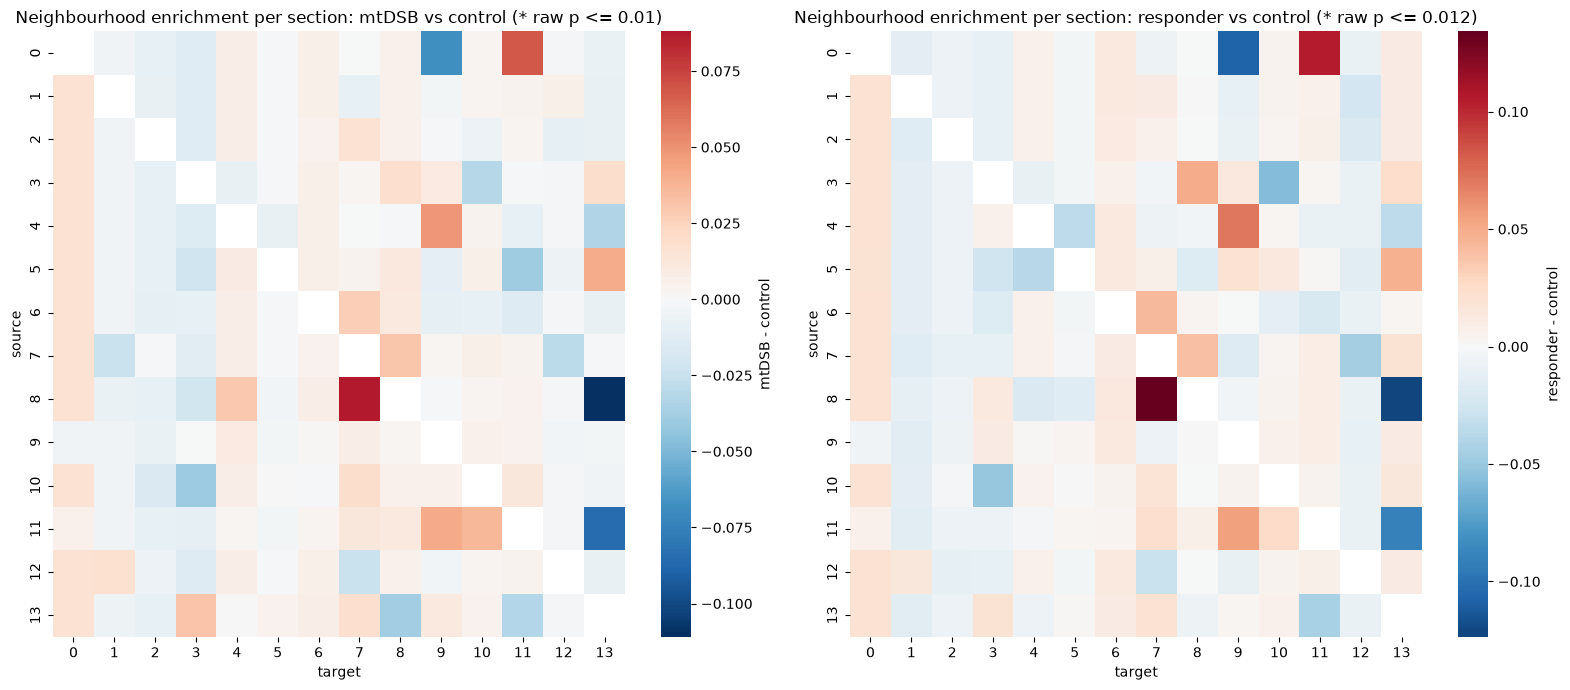

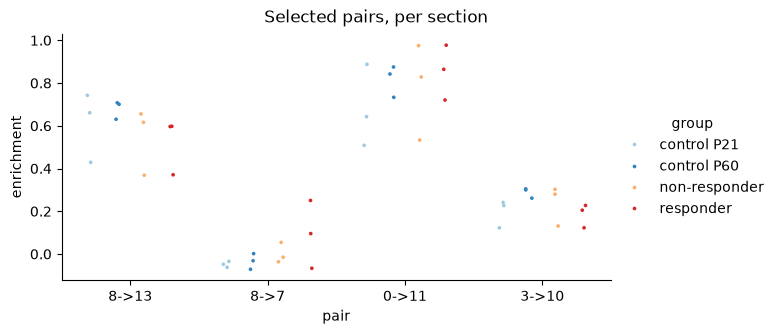

In [9]:
fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(16, 7))
for ax, (name, kw) in zip(axes, COMPARISONS.items()):
    r = nh_res[nh_res['comparison'] == name]
    E = r.pivot(index='source', columns='target', values='effect').reindex(index=COMP_ORDER, columns=COMP_ORDER)
    P = r.pivot(index='source', columns='target', values='p_perm').reindex(index=COMP_ORDER, columns=COMP_ORDER)
    star = 0.01 if kw['strata_key'] == TP else 0.012     # near the smallest possible p of each design
    sns.heatmap(E, cmap='RdBu_r', center=0, annot=P.map(lambda p: '*' if p <= star else ''), fmt='', ax=ax,
                cbar_kws={'label': f"{kw['treat']} - control"})
    ax.set_title(f'Neighbourhood enrichment per section: {name} (* raw p <= {star})')
fig.tight_layout()
fig.savefig(f'{RES}/nhood_per_section_effect.png', dpi=150, bbox_inches='tight')

pairs = [('8', '13'), ('8', '7'), ('0', '11'), ('3', '10')]
d = pd.concat([nh_long[(nh_long.source == a) & (nh_long.target == b)].assign(pair=f'{a}->{b}') for a, b in pairs])
strip_by_mouse(d, x='pair', y='enrichment', aspect=2, title='Selected pairs, per section',
               fname='nhood_selected_pairs_per_mouse.png')

## 4. Pseudobulk DE in the myelinated compartments
Counts summed per mouse (min 50 cells), PyDESeq2, contrast treat vs control:
- mtDSB vs control: `~ timepoint + condition` (12 mice);
- responder vs control: `~ timepoint + responder_status` (9 mice; non-responders dropped).

Groups:
- **all cells** of compartment 3 / 10: mixes composition changes (more microglia, DA-OLs) with expression changes;
- **per cell type** inside the compartment: expression changes within a cell type. Mature OLs are taken as OL + DA-OL
  together, otherwise the DA-OL state would be removed from the comparison by construction.


In [10]:
GROUPS = {
    'all cells': None,
    'mature OL (OL + DA-OL)': ['Oligodendrocytes', 'DA-Oligodendrocytes'],
    'Microglia': ['Microglia'],
    'Astrocytes': ['Astrocytes'],
}
DESIGNS = {'mtDSB vs control': f'~{TP} + {COND}', 'responder vs control': f'~{TP} + {RESP}'}

def group_mask(comp, types):
    return ((obs[COMP] == comp) & (obs[CT_WORK].isin(types) if types else True)).values

de = {}
for comp in PRIMARY:
    for gname, types in GROUPS.items():
        counts, meta = cs.pseudobulk(adata[group_mask(comp, types)].to_memory(), [SAMPLE, COND, TP, RESP], min_cells=50)
        for name, kw in COMPARISONS.items():
            keep = meta[kw['cond_key']].isin([kw['treat'], kw['ref']])
            m = meta[keep]
            if (m[kw['cond_key']] == kw['treat']).sum() < 3 or (m[kw['cond_key']] == kw['ref']).sum() < 3:
                print(f'skip {comp} / {gname} / {name}: too few mice with >= 50 cells'); continue
            res = cs.run_pydeseq2(counts[keep], m[[kw['cond_key'], TP]], design=DESIGNS[name],
                                  contrast=(kw['cond_key'], kw['treat'], kw['ref']))
            de[(comp, gname, name)] = res
            tag = name.split(' ')[0]
            res.to_csv(f"{RES}/pseudobulk_DE_comp{comp}_{gname.split(' ')[0]}_{tag}.csv")
            print(f'comp {comp} | {gname:24s} | {name:22s} | mice {len(m):2d} | padj<0.1: {(res.padj < 0.1).sum()}')

comp 3 | all cells                | mtDSB vs control       | mice 12 | padj<0.1: 41
comp 3 | all cells                | responder vs control   | mice  9 | padj<0.1: 596
comp 3 | mature OL (OL + DA-OL)   | mtDSB vs control       | mice 12 | padj<0.1: 62
comp 3 | mature OL (OL + DA-OL)   | responder vs control   | mice  9 | padj<0.1: 633
comp 3 | Microglia                | mtDSB vs control       | mice 12 | padj<0.1: 7
comp 3 | Microglia                | responder vs control   | mice  9 | padj<0.1: 281
comp 3 | Astrocytes               | mtDSB vs control       | mice 12 | padj<0.1: 7
comp 3 | Astrocytes               | responder vs control   | mice  9 | padj<0.1: 101
comp 10 | all cells                | mtDSB vs control       | mice 12 | padj<0.1: 11
comp 10 | all cells                | responder vs control   | mice  9 | padj<0.1: 319
comp 10 | mature OL (OL + DA-OL)   | mtDSB vs control       | mice 12 | padj<0.1: 7
comp 10 | mature OL (OL + DA-OL)   | responder vs control   | mice  9 |

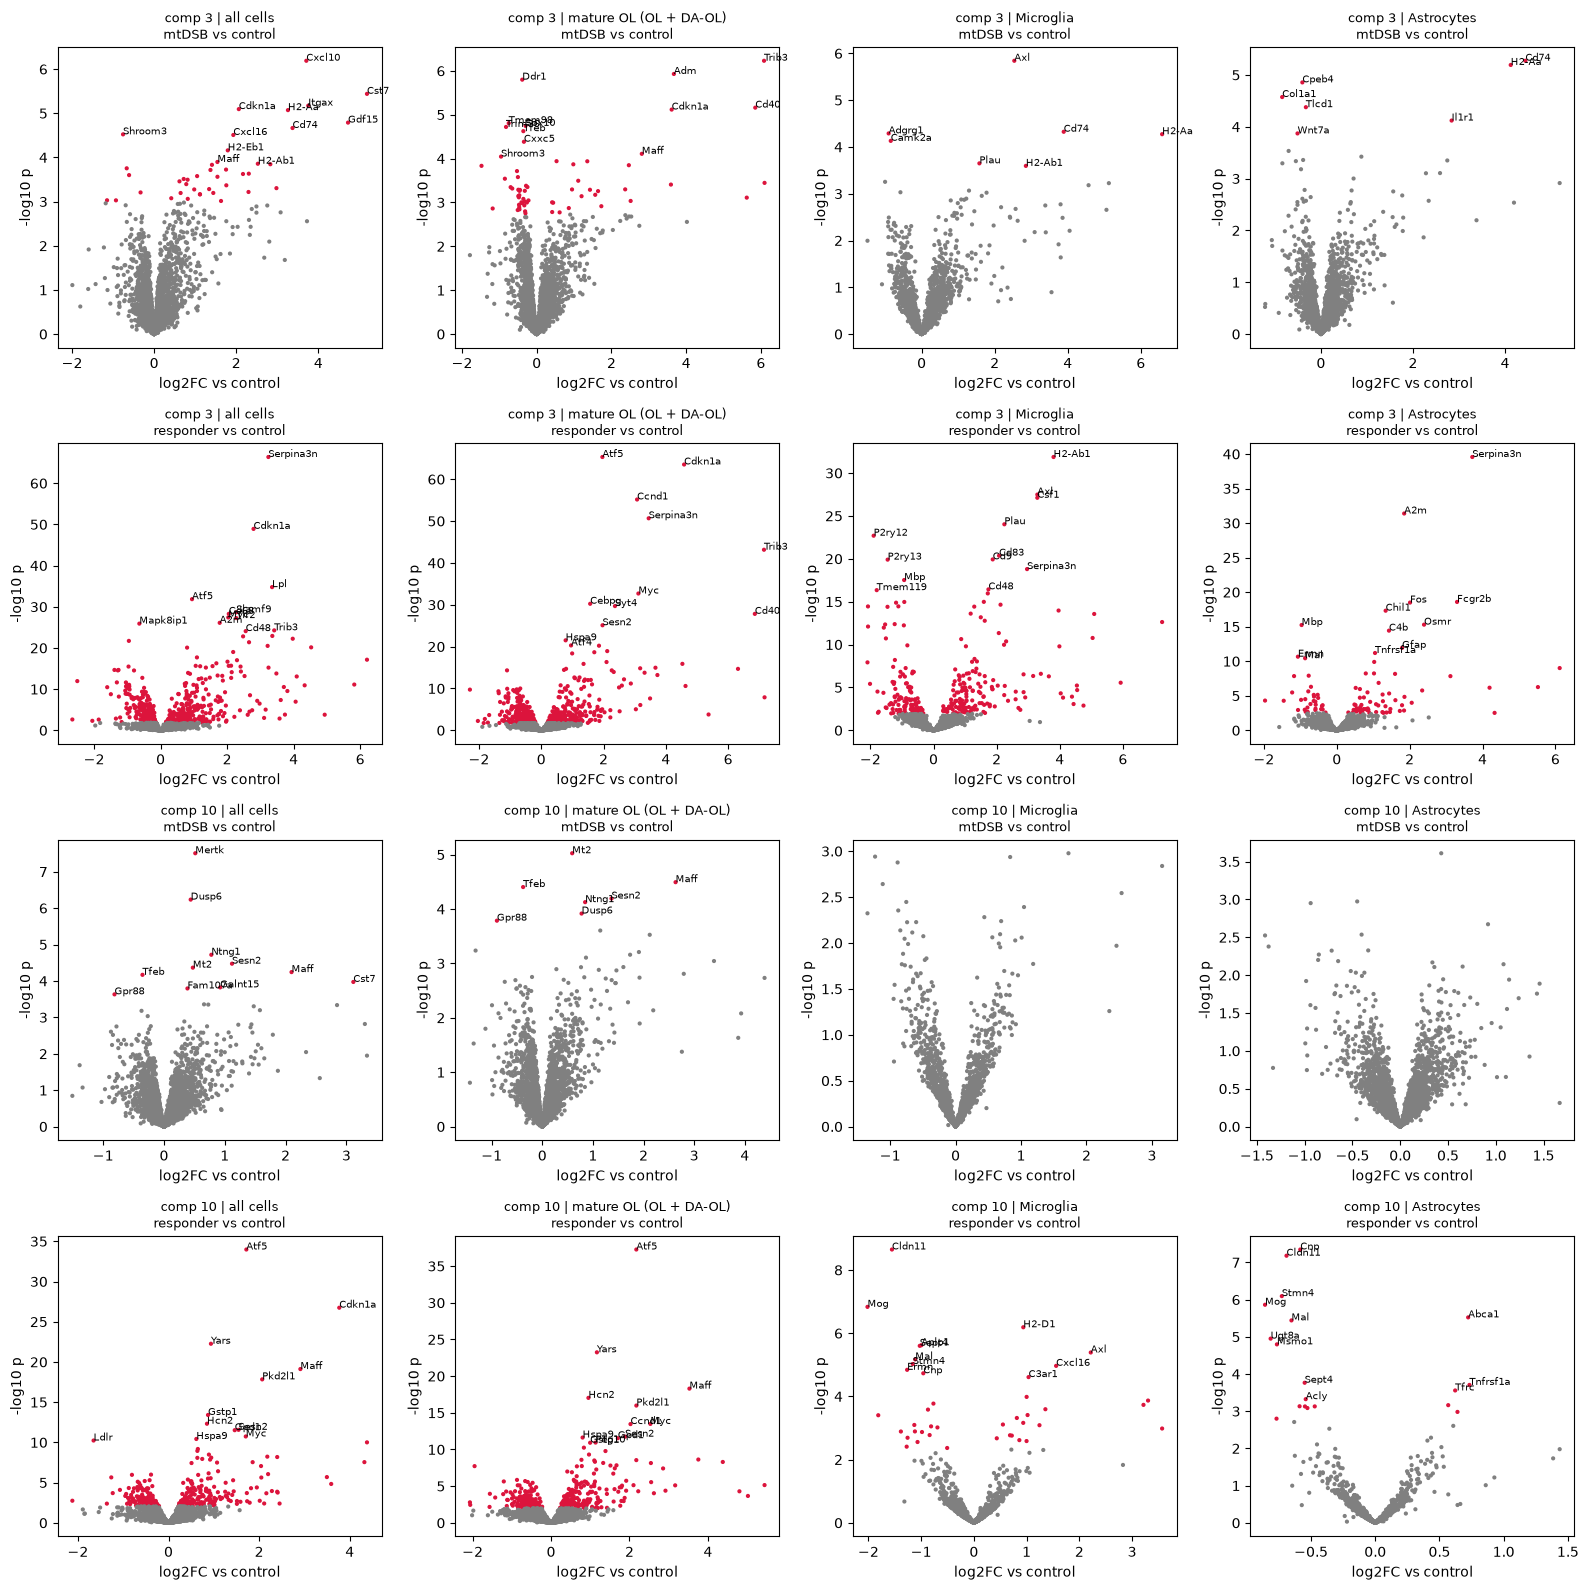

In [11]:
rows = [(comp, name) for comp in PRIMARY for name in COMPARISONS]
fig, axes = plt.subplots(len(rows), len(GROUPS), figsize=(4 * len(GROUPS), 4 * len(rows)), squeeze=False)
for i, (comp, name) in enumerate(rows):
    for j, gname in enumerate(GROUPS):
        ax = axes[i, j]
        if (comp, gname, name) not in de:
            ax.axis('off'); continue
        r = de[(comp, gname, name)].dropna(subset=['padj'])
        sig = r['padj'] < 0.1
        ax.scatter(r['log2FoldChange'], -np.log10(r['pvalue']), s=4, c=np.where(sig, 'crimson', 'grey'))
        for gene, row in r[sig].head(12).iterrows():
            ax.annotate(gene, (row['log2FoldChange'], -np.log10(row['pvalue'])), fontsize=7)
        ax.set_title(f'comp {comp} | {gname}\n{name}', fontsize=9)
        ax.set_xlabel('log2FC vs control'); ax.set_ylabel('-log10 p')
fig.tight_layout()
fig.savefig(f'{RES}/pseudobulk_DE_volcanos.png', dpi=150, bbox_inches='tight')

Per-mouse view of the top genes.

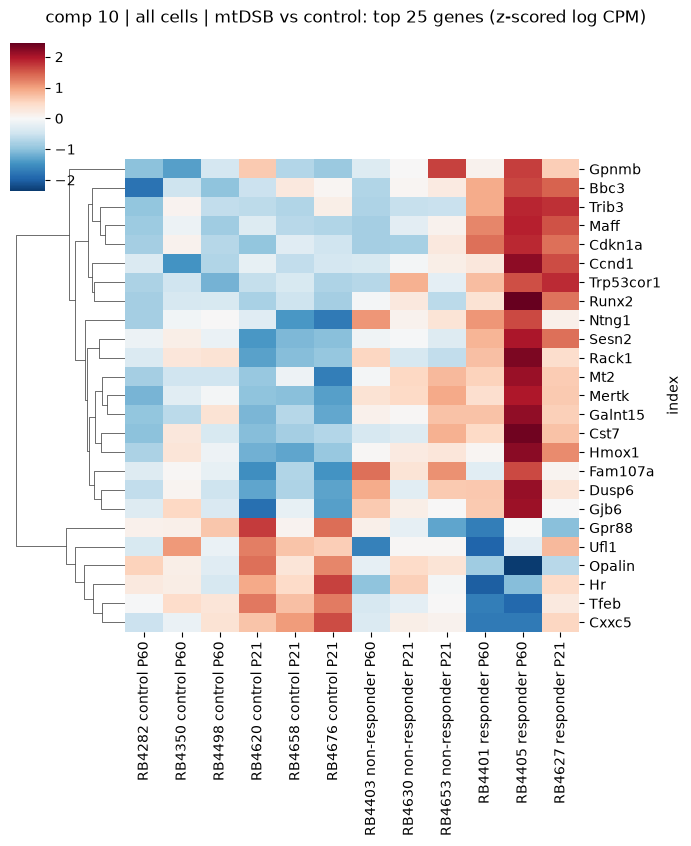

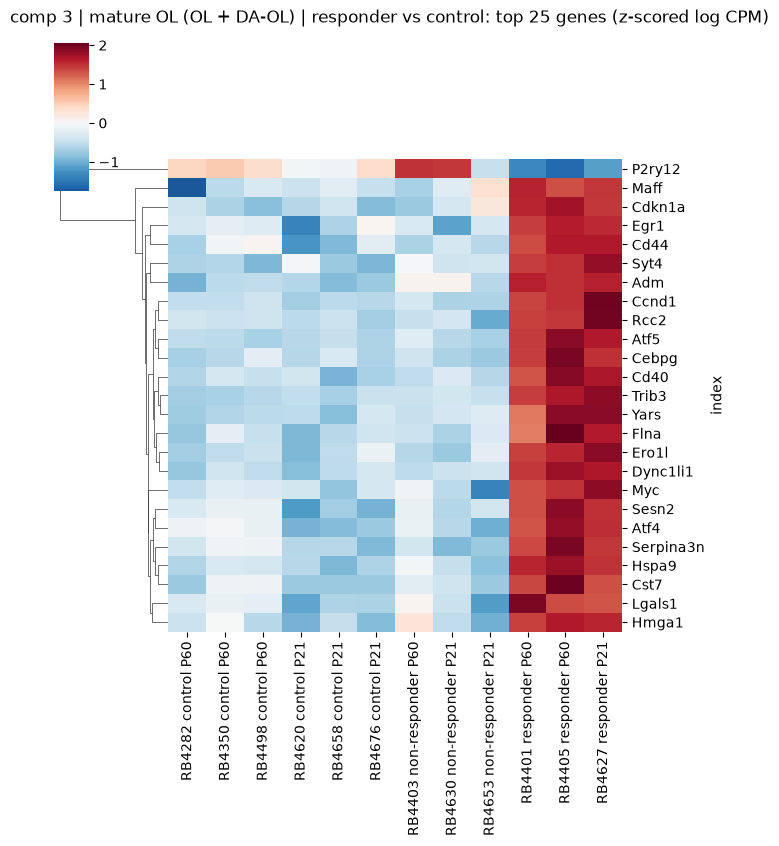

In [12]:
def per_mouse_heatmap(comp, gname, name, n=25):
    counts, meta = cs.pseudobulk(adata[group_mask(comp, GROUPS[gname])].to_memory(), [SAMPLE, COND, TP, RESP],
                                 min_cells=50)
    genes = de[(comp, gname, name)].dropna(subset=['padj']).head(n).index
    logcpm = np.log1p(counts.div(counts.sum(1), axis=0) * 1e6)[genes]
    logcpm.index = meta[SAMPLE] + ' ' + meta[RESP].astype(str) + ' ' + meta[TP]
    order = sorted(logcpm.index, key=lambda s: (['control', 'non-responder', 'responder'].index(s.split(' ')[1]), s))
    z = ((logcpm - logcpm.mean()) / logcpm.std()).loc[order]
    g = sns.clustermap(z.T, col_cluster=False, cmap='RdBu_r', center=0, figsize=(7, 0.25 * n + 2))
    g.figure.suptitle(f'comp {comp} | {gname} | {name}: top {n} genes (z-scored log CPM)', y=1.02)
    g.savefig(f"{RES}/pseudobulk_top_genes_comp{comp}_{gname.split(' ')[0]}_{name.split(' ')[0]}.png",
              dpi=150, bbox_inches='tight')

per_mouse_heatmap('10', 'all cells', 'mtDSB vs control')
per_mouse_heatmap('3', 'mature OL (OL + DA-OL)', 'responder vs control')